<a href="https://colab.research.google.com/github/chrismji/Datasci-and-Ai-in-Bus/blob/main/HW4_TelcoChurn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting MegaTelCo Churn

After discussing the churn problem at TelCo with Nadia for a while (remember her?), you've finally defined an adequate target variable for churn and gathered relevant data to predict it. Moreover, the marketing department has come up with an amazing retention offer: the offer is guaranteed to convince customers to extend their contract for an extra year after receiving it. Unfortunately, the offer is quite expensive; it costs $200. __You have enough budget to give the retention offer to up to 25% of the customers whose contracts are expiring.__

It is your job to use data from previous contract expirations to build a churn predictive model and make a recommendation of whom to target with the offers. You have assembled the best historical data set you can at this point, which includes:

- Gender: Whether the customer is a male or a female
- SeniorCitizen: Whether the customer is a senior citizen or not (1, 0)
- Partner: Whether the customer has a partner or not (Yes, No)
- Dependents: Whether the customer has dependents or not (Yes, No)
- Tenure: Number of months the customer has stayed with the company
- PhoneService: Whether the customer has a phone service or not (Yes, No)
- MultipleLines: Whether the customer has multiple lines or not (Yes, No, No phone service)
- InternetService: Customer’s internet service provider (DSL, Fiber optic, No)
- OnlineSecurity: Whether the customer has online security or not (Yes, No, No internet service)
- OnlineBackup: Whether the customer has online backup or not (Yes, No, No internet service)
- DeviceProtection: Whether the customer has device protection or not (Yes, No, No internet service)
- TechSupport: Whether the customer has tech support or not (Yes, No, No internet service)
- StreamingTV: Whether the customer has streaming TV or not (Yes, No, No internet service)
- StreamingMovies: Whether the customer has streaming movies or not (Yes, No, No internet service)
- Contract: The contract term of the customer (Month-to-month, One year, Two year)
- PaperlessBilling: Whether the customer has paperless billing or not (Yes, No)
- PaymentMethod: The customer’s payment method (Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic))
- MonthlyCharges: The amount charged to the customer monthly
- Churn: Whether the customer churned or not shortly after contract expiration (Yes or No)

In [34]:
#load important packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree



In [35]:
import warnings
warnings.filterwarnings("ignore")

**1. Load the churn data [click here to download data](https://drive.google.com/uc?download&id=1xMMPIFOooEzcrdDFNFYvId5aROmTuzxv):**

**Use `get_dummies` to transform the categorical features into dummy features. (use `drop_first=True`)**

In [36]:
df = pd.read_csv('telco_churn.csv')
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,Yes


In [37]:
df = pd.get_dummies(df, drop_first=True, dtype=int)
df.head()

,SeniorCitizen,tenure,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,1,29.85,0,1,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
1,0,34,56.95,1,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,1,0
2,0,2,53.85,1,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,1
3,0,45,42.30,1,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
4,0,2,70.70,0,0,0,1,0,0,1,...,0,0,0,0,0,1,0,1,0,1


__2. _Of course_ normally we would do some detailed exploratory work!  But we have high confidence in the data quality and there are no missing values, so lets proceed. `Tenure` is often a key churn feature.  Make a plot to gain insight the relationship between Tenure and probability of Churn.   Comment on the relationship - does this look like a linear or non-linear effect?__


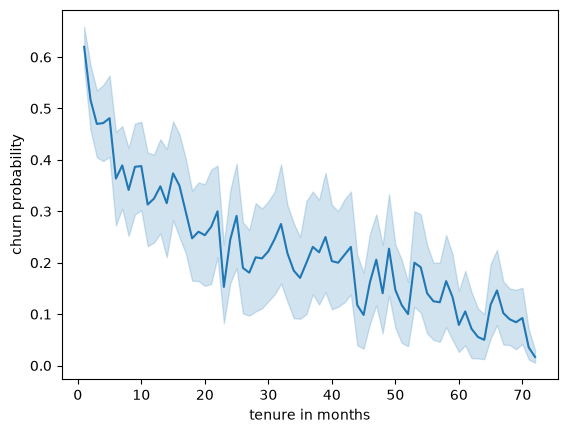

In [38]:
sns.lineplot(data=df, x='tenure', y='Churn_Yes')
plt.xlabel('tenure in months')
plt.ylabel('churn probability')
plt.show()

- It seems like a negative correlation-- the longer you are tenured, the lowere the probability of a churn.
- It doesn't seem linear, given the steep drop off from 0-10, and then steady decline afterwards

__3. Define X and y and split your data into Training and Test using an 80/20 split (you may consider setting a `random_state` for reproducibility)__

__Build the best model you can on the TRAINING set using a decision tree classifier.  Do a grid search over the hyperparameters `max_depth` and `min_samples_leaf`.  Use GridSearchCV with the following instructions:__
- search `max_depth` within the range of [2,15]
- search `min_samples_leaf` within the range [1,100] (in steps of 10)
- 5-fold CV
- use AUC as the `scoring` function ("roc_auc")

**Report the optimal values of the parameters `min_samples_leaf` and `max_depth` and the AUC associated with it. Define a model `tree_best` that uses your optimized value of `min_samples_leaf` and `max_depth` and fit it to the 80% training data.**

In [39]:
X = df.drop(columns=['Churn_Yes'])
y = df['Churn_Yes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

params = {'max_depth': range(2, 16), 'min_samples_leaf': range(1, 101, 10)}

tree = DecisionTreeClassifier(random_state=42)

grid = GridSearchCV(tree,param_grid=params,cv=5,scoring='roc_auc')

grid.fit(X_train, y_train)

print(f'best parameters: {grid.best_params_}')
print(f'best AUC: {round(grid.best_score_, 4)}')

best parameters: {'max_depth': 6, 'min_samples_leaf': 31}
best AUC: 0.8302


In [40]:
tree_best = DecisionTreeClassifier(max_depth=grid.best_params_['max_depth'], min_samples_leaf=grid.best_params_['min_samples_leaf'], random_state=42)

tree_best.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",31
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

**4. Calculate the feature importances.  For the top 5 most important features, explain whether you think they would be positively or negatively correlated with churn.**

In [41]:
importances = pd.Series(tree_best.feature_importances_,index=X_train.columns).sort_values(ascending=False)

print(importances.head(5))

tenure                                0.460471
InternetService_Fiber optic           0.321031
MonthlyCharges                        0.040081
PaymentMethod_Electronic check        0.038546
OnlineSecurity_No internet service    0.025372
dtype: float64


1. Tenure: as we saw, this one has a negative correlation with churn; the longer someone has stayed with the company the less likely they are to churn
2. Fiber optic-- I think that this will have a positive correlation with churn. Fiber optic is the most advanced/fastest/most expensive form of internet. At that price range and quality, I think that there will be more competition and customers paying that much would be more willing to swap to competitors for better service and/or lower prices.
3. Monthly charges should have a positive correlation with churn. The more expensive the internet bill is, the more likely a customer would want to switch.
4. Electronic check I think would also have a positive correlation with churn. Compared to a scheduled auto-payment from your bank, it is much quicker for customers to switch, by simply stopping the payment of their internet service.
5. No internet service-- this should have a negative correlation with churn, essentially for the opposite reasons of fiber optic. It's the simplest, most barebones, and cheapest form of play, so customers would be less likely to switch.

**5.  Now fit Lasso Regression (`LogisticRegression()` with `penalty = 'l1'`) to the Training set and use GridSearch or a for loop to find the best value of the hyperparameter C:  `C=[0.01,.1,.5,1,5,10,50,100]`.  Report on the optimal value of C.  Define a model `lr_best` that uses these parameters.**


In [42]:
lr = LogisticRegression(penalty='l1', solver='liblinear', max_iter=5000)

params = {'C': [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]}

grid_lr = GridSearchCV(lr, params, cv=5, scoring='roc_auc')

grid_lr.fit(X_train, y_train)

print(f'best c: {grid_lr.best_params_['C']}')
print(f'best AUC: {grid_lr.best_score_}')

best c: 50
best AUC: 0.844566634544527


In [43]:
lr_best = LogisticRegression(penalty='l1', solver='liblinear', C=grid_lr.best_params_['C'], max_iter=5000)

lr_best.fit(X_train, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",50
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the 

**6. Print the regularized coefficient values in `lr_best`.  How many of the Lasso coefficients have shrunken all the way to zero (use 4 decimal places)?  Interpret what you learn from these coefficients.**

In [44]:
coefficients = pd.Series(lr_best.coef_[0], index=X_train.columns).round(4)

print(coefficients)

SeniorCitizen                            0.1931
tenure                                  -0.0329
MonthlyCharges                          -0.0635
gender_Male                             -0.0186
Partner_Yes                             -0.0301
Dependents_Yes                          -0.2424
PhoneService_Yes                         0.9818
MultipleLines_No phone service           0.2297
MultipleLines_Yes                        0.6583
InternetService_Fiber optic              2.4910
InternetService_No                      -0.1781
OnlineSecurity_No internet service      -0.1849
OnlineSecurity_Yes                      -0.0867
OnlineBackup_No internet service        -0.1851
OnlineBackup_Yes                         0.1670
DeviceProtection_No internet service    -0.1928
DeviceProtection_Yes                     0.3671
TechSupport_No internet service         -0.1762
TechSupport_Yes                         -0.0389
StreamingTV_No internet service         -0.1719
StreamingTV_Yes                         

**7.  Use your toolbox!! Now pick a third classification model of your choice. You can use something we learned in class (SVM, MLPClassifier) or something else you maybe know of (kNN, RandomForest, Linear Discriminant).  Fit the model - you can use default hyperparameters (dont worry about optimizing) - and see how well it does (AUC).**


In [45]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_probs = rf.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_probs)

print(f'rf auc: {round(rf_auc, 4)}')

rf auc: 0.8119


__8. Using your TEST data plot the ROC Curves for each of the three models.  You will need to use the predicted probabilities from each model applied to the TEST set and the `roc_curve()` function - make sure to plot the three curves together on the same plot. The plot should have a legend.  Review the AUC values to identify the best of these three.  Which one is best? Call this `best_model`.__

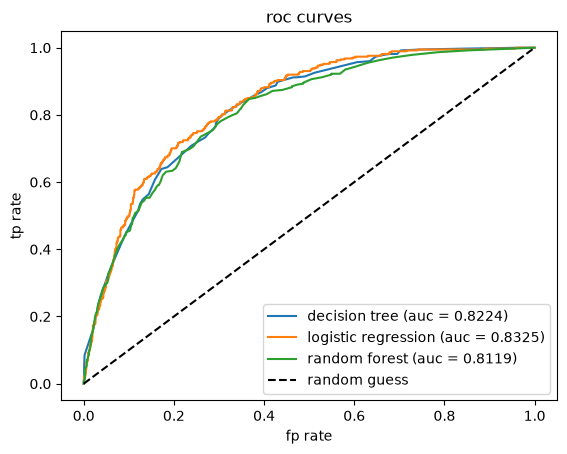

In [46]:
models = {
    'decision tree': tree_best,
    'logistic regression': lr_best,
    'random forest': rf
}

auc_scores = {}

for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    auc_scores[name] = auc

    plt.plot(fpr, tpr, label=f'{name} (auc = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='random guess')

plt.xlabel('fp rate')
plt.ylabel('tp rate')
plt.title('roc curves')
plt.legend()
plt.show()


In [47]:
best = max(auc_scores, key=auc_scores.get)
best_model = models[best]

print(f'best auc: {best} @ {round(auc_scores[best], 4)}')

best auc: logistic regression @ 0.8325


__9. What is the cost / benefit matrix for implementing this model?  HINT: The cost is given in the problem description.  Remember that everyone who receives the offer takes it. The benefit comes when we make the offer to a customer whose actual Churn value is 1.  (i.e. they would have left us but we saved them).   We can assume each customer generates the same revenue - equal to the average of `MonthlyCharges`. Report the benefit as a YEARLY value.__

In [48]:
cost = 200
benefit = df['MonthlyCharges'].mean() * 12

print(f'yearly benefit: {round(benefit, 2)}')
print(f'net benefit: {round(benefit - cost, 2)}')

cost_benefit = pd.DataFrame(
    [[benefit - cost, -cost],
     [0, 0]],
    index=['Offer', 'No Offer'],
    columns=['Actual Churn', 'Actual No Churn']
)

cost_benefit

yearly benefit: 777.58
net benefit: 577.58


,Actual Churn,Actual No Churn
Offer,577.578498,-200
No Offer,0.000000,0


__10. Using `best_model` -  along with the cost/benefit matrix - now we want to look at profit.  Plot a *PROFIT CURVE* that shows the overall profit at different levels of marketing.  You'll need to sort the threshold probabilities, and calculate the profit at each threshold by determining who you market to and who you dont.  Use your cost/benefit numbers to calculate total profit at each threshold value. (You may want to refer back to the`T5_Model_assessment` notebook)__

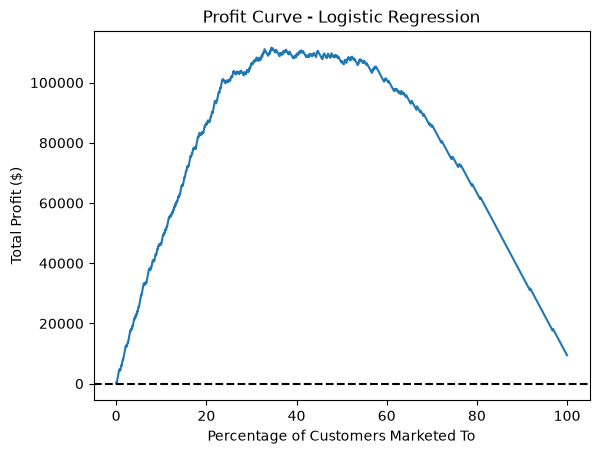

In [ ]:
probs = best_model.predict_proba(X_test)[:, 1]

order = np.argsort(probs, descending=True)
y_sorted = np.array(y_test)[order]

customers = np.arange(len(y_sorted) + 1)
tp = np.concatenate(([0], np.cumsum(y_sorted)))

profit = tp * benefit - customers * cost

pct_marketed = customers / len(y_sorted) * 100

plt.plot(pct_marketed, profit)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Percentage of Customers Marketed To')
plt.ylabel('Total Profit ($)')
plt.title('Profit Curve - Logistic Regression')
plt.show()

**11. Recall that Nadia told you there is only budget to market to the top 25% of customers.  Make a pitch to her for altering that decision based on your Profit curve.  How much do you recommend marketing to, and how much money will it make compared to her threshold?**

__12. Assume Nadia was persuaded by your pitch and this model was deployed - and it performed as expected.  Now it is performance review season, and you are looking for a raise!!
Estimate the amount of money you made for the company by using your model.  Compare your profit above against a "dumb" model of marketing to the same amount of customers in the Test set who are selected randomly. (Hint: you can use a random number generator to pick customers at random to market to, and see what their profit would be).   Scale your results up to the overall consumer base of 100,000 customers to make your case.__

__13.  (Extra Credit):  In the above exercise we assumed the benefit of each customer was the same.  But it would be even better to incorporate each customer's individual spending in the cost/benefit!! Calculate an *individualized expected value* for profit/loss for _each customer_ using their specific Monthly Charges and their calculated probability of churn.    You'll need to calculate Expected Value for each customer (using the individualized Monthly Charges) and use the sorted Expected Value to draw the line of whom to market to - and to calculate profit.   Are the results any better?__